# Granular Synthesis with granulate

`granulate` reassembles an input into overlapping grains: time-stretching without pitch change, sound clouds, and "frozen" textures. Every grain parameter is audible.

Source: [CLM generators -- granulate](https://ccrma.stanford.edu/software/snd/snd/sndclm.html)

In [1]:
import os, importlib
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

import pysndlib.clm as clm

SR = 44100

examples_dir = os.path.dirname(importlib.import_module('pysndlib.examples').__file__)
EXAMPLE = os.path.join(examples_dir, 'flute_trill_1.wav')
print('source file:', EXAMPLE)

def granulate_file(name, out, dur=2.0, **params):
    """run granulate over the example file for dur seconds"""
    with clm.Sound(out, channels=1, srate=SR):
        reader = clm.make_readin(EXAMPLE)
        gen = clm.make_granulate(reader, **params)
        for i in range(int(dur * SR)):
            clm.outa(i, clm.granulate(gen))
    d, _ = clm.file2ndarray(out)
    return d[0]

source file: /Users/toddingalls/Developer/Python/pysndlib/src/pysndlib/examples/flute_trill_1.wav


## The parameters

- `expansion`: output time / input time (> 1 slows the source down)
- `hop`: seconds between grain onsets (density)
- `length`: grain length in seconds
- `ramp`: grain attack/decay fraction (0.4 = smooth trapezoid)
- `scaler`: grain amplitude scaling
- `jitter`: randomness in grain start times

In [2]:
# the source, for reference
src_data, _ = clm.file2ndarray(EXAMPLE)
ipd.Audio(EXAMPLE, rate=SR)

In [3]:
slowed = granulate_file('slow', 'gran_slow.wav', expansion=3.0)

In [4]:
ipd.Audio('gran_slow.wav', rate=SR)

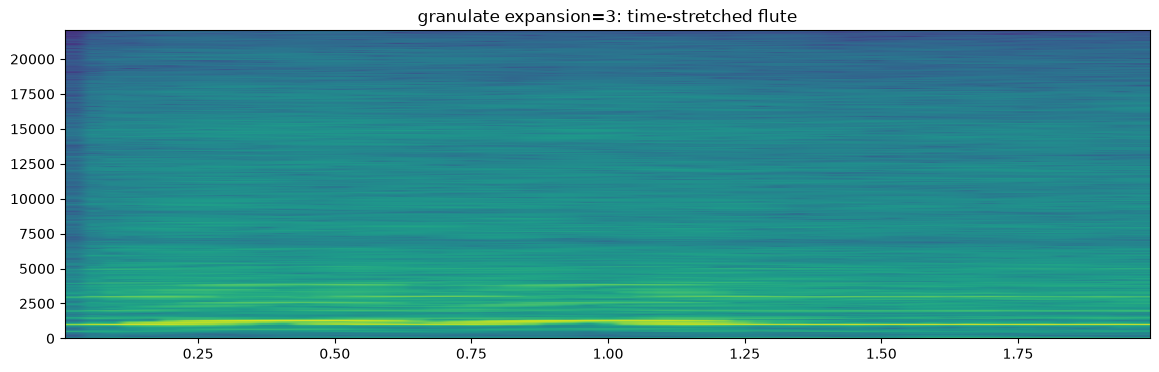

In [5]:
plt.figure(figsize=(14, 4))
plt.specgram(slowed, NFFT=2048, Fs=SR, noverlap=512)
plt.title('granulate expansion=3: time-stretched flute'); plt.show()

## Density: hop

In [6]:
dense = granulate_file('dense', 'gran_dense.wav', hop=0.01, scaler=0.25)
sparse = granulate_file('sparse', 'gran_sparse.wav', hop=0.2, scaler=0.6)

In [7]:
ipd.Audio('gran_dense.wav', rate=SR)

In [8]:
ipd.Audio('gran_sparse.wav', rate=SR)

In [ ]:
plt.figure(figsize=(14, 4))
plt.specgram(dense[:SR * 2], NFFT=1024, Fs=SR, noverlap=256, cmap='magma')
plt.title('dense cloud (hop=0.01)'); plt.show()

## Grain shape: ramp and length

In [9]:
clicky = granulate_file('clicky', 'gran_clicky.wav', ramp=0.05, length=0.05, hop=0.08, scaler=0.5)
smooth = granulate_file('smooth', 'gran_smooth.wav', ramp=0.5, length=0.3, hop=0.08, scaler=0.5)

In [10]:
ipd.Audio('gran_clicky.wav', rate=SR)

In [11]:
ipd.Audio('gran_smooth.wav', rate=SR)

## Jitter: organic vs mechanical

In [ ]:
mech = granulate_file('mech', 'gran_mech.wav', hop=0.15, jitter=0.04, scaler=0.4)
organic = granulate_file('organic', 'gran_organic.wav', hop=0.05, jitter=0.04, scaler=0.4)

In [20]:
ipd.Audio('gran_mech.wav', rate=SR)

In [18]:
ipd.Audio('gran_organic.wav', rate=SR)

## Feeding granulate from a function

The input can be a Python callable (it receives the direction argument and returns the next input value). Here the "input" is a live oscillator, so the granulator reassembles something that never existed in a file:

In [ ]:
with clm.Sound('gran_live.wav', channels=1, srate=SR):
    osc = clm.make_oscil(330.0)
    vib = clm.make_rand_interp(6.0, amplitude=100.0)
    def live_input(direction):
        return clm.oscil(osc, clm.rand_interp(vib))
    gen = clm.make_granulate(live_input, expansion=1.5, hop=0.04, scaler=0.5)
    for i in range(2 * SR):
        clm.outa(i, clm.granulate(gen))

In [ ]:
ipd.Audio('gran_live.wav', rate=SR)

## Summary

- expansion stretches time; hop sets density; ramp/length shape each grain
- jitter humanizes the placement; inputs can be files or functions
- granulate is the texture tool: compare with [the phase vocoder](13_Phase_Vocoder.ipynb)